<a href="https://colab.research.google.com/github/28-adityakishan-ai/DAP-LECTURE-/blob/main/lecture%2014%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

lecture 9 and 10

In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
import numpy as np

df = pd.read_excel("/content/Zepto_Orders_Data (1).xlsx", sheet_name="Orders")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])

df.head()

Saving Zepto_Orders_Data (1).xlsx to Zepto_Orders_Data (1) (2).xlsx
Rows: 1200 | Columns: 14


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
0,ZP-0001,2026-07-01,Afternoon,Haryana,Gurugram,Snacks & Drinks,Pass Member,Clear,1.1,7,755,18,9,4.9
1,ZP-0002,2026-07-01,Evening,Tamil Nadu,Chennai,Household Items,Pass Member,Clear,1.9,5,835,0,8,5.0
2,ZP-0003,2026-07-01,Afternoon,NCT of Delhi,Delhi,Dairy & Bread,Pass Member,Clear,0.3,5,605,20,9,4.7
3,ZP-0004,2026-07-01,Late Night,Uttar Pradesh,Noida,Snacks & Drinks,Pass Member,Clear,3.7,5,420,20,19,4.5
4,ZP-0005,2026-07-01,Evening,Kerala,Kochi,Dairy & Bread,New User,Clear,0.5,10,670,39,8,5.0


In [ ]:
df.describe().round(1)

,Order_Date,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
count,1200,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,2026-08-20 19:57:36,1.6,4.9,422.9,15.5,13.0,4.5
min,2026-07-01 00:00:00,0.3,1.0,50.0,0.0,4.0,2.8
25%,2026-07-31 00:00:00,0.8,3.0,230.0,8.0,9.0,4.2
50%,2026-08-23 00:00:00,1.3,5.0,350.0,14.0,12.0,4.6
75%,2026-09-12 00:00:00,2.2,6.0,560.0,22.0,16.0,4.9
max,2026-09-30 00:00:00,4.0,11.0,2230.0,46.0,31.0,5.0
std,NaN,1.0,2.0,270.3,9.9,4.9,0.4


In [ ]:
df["State"].value_counts()

,count
State,
Karnataka,223
NCT of Delhi,188
Maharashtra,182
Telangana,113
Haryana,107
Tamil Nadu,107
Uttar Pradesh,94
Gujarat,55
West Bengal,54


In [ ]:
# Step 3 | Prepare helper columns

df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

df["Weekday"] = df["Order_Date"].dt.day_name()

df["Within_10_Min"] = df["Delivery_Time_Min"] <= 10
# True if we kept the promise

# Fixed orders so charts always show groups in a sensible order

slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]

type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

,Order_Date,Week,Weekday,Within_10_Min
0,2026-07-01,27,Wednesday,True
1,2026-07-01,27,Wednesday,True
2,2026-07-01,27,Wednesday,True
3,2026-07-01,27,Wednesday,False
4,2026-07-01,27,Wednesday,True


how many time delivery take

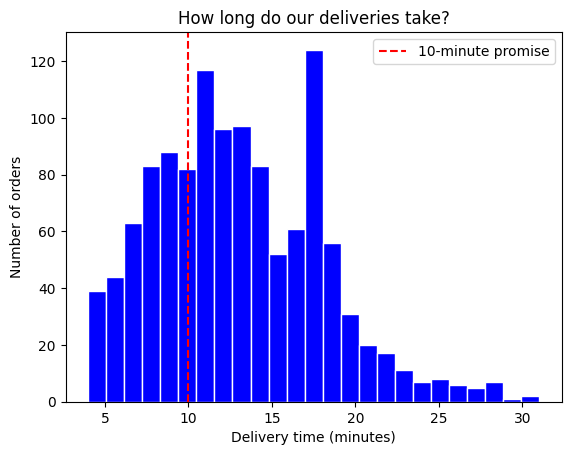

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df['Delivery_Time_Min'], bins=25, color='blue', edgecolor='white')

plt.axvline(10, color='red', linestyle='--', label='10-minute promise')

plt.title('How long do our deliveries take?')

plt.xlabel('Delivery time (minutes)')

plt.ylabel('Number of orders')

plt.legend()

plt.show()

bar plot

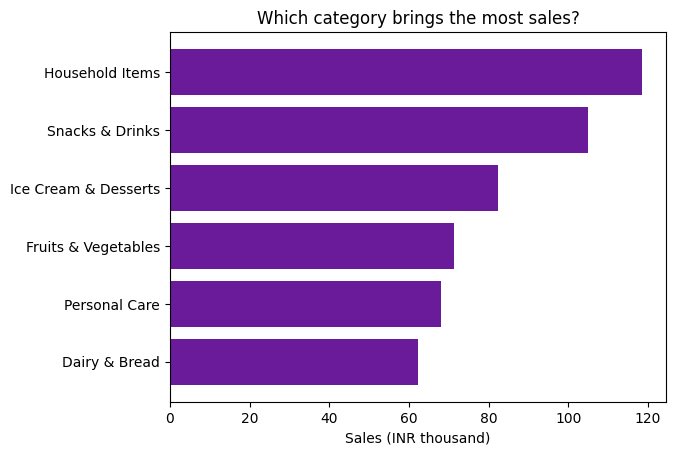

In [ ]:


category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

plt.barh(
    category_sales.index,
    category_sales.values / 1000,
    color="#6A1B9A"
)

plt.title("Which category brings the most sales?")

plt.xlabel("Sales (INR thousand)")

plt.show()


are orders growing week by week?


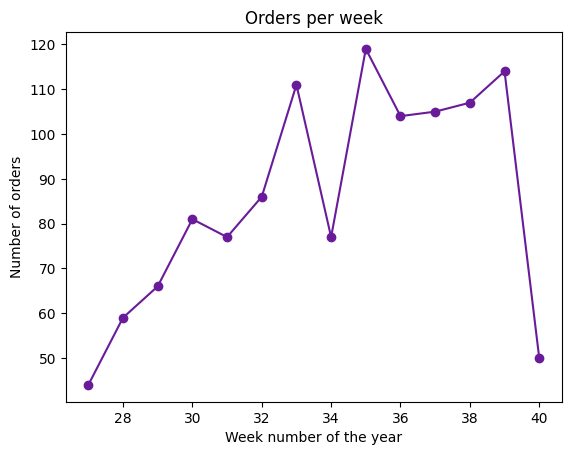

In [ ]:
import matplotlib.pyplot as plt

# Ensure the 'Week' column is present before grouping
if "Week" not in df.columns:
    df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

# Weekly order analysis
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(
    weekly_orders.index,
    weekly_orders.values,
    marker="o",
    color="#6A1B9A"
)

plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

area plot


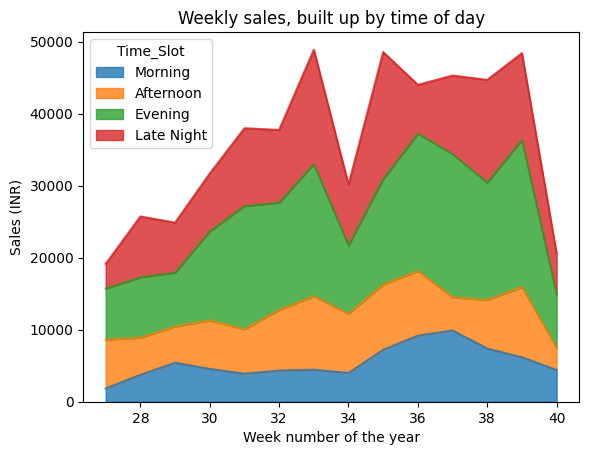

In [ ]:
import matplotlib.pyplot as plt

# Ensure the 'Week' column is present before pivoting
if "Week" not in df.columns:
    df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

# Ensure slot_order is defined
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]

# Pivot and plot
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

does a longer distance mean a slower deliveer and does a slower delivery mean a lower rating?


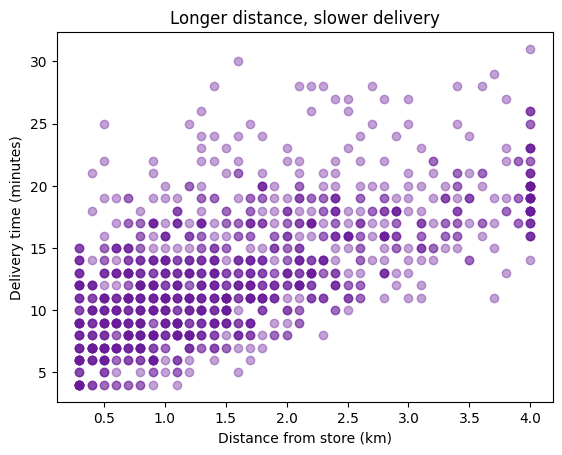

In [ ]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

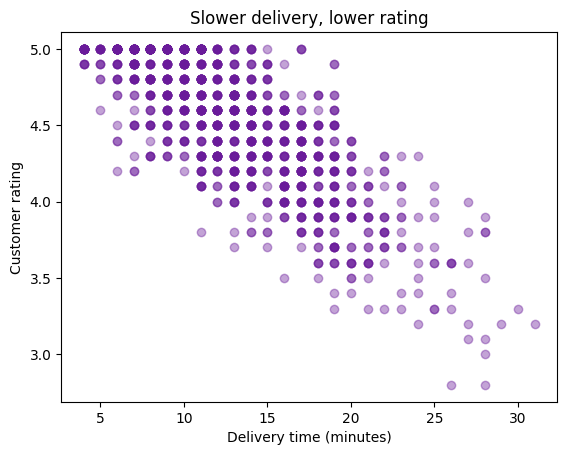

In [ ]:
plt.scatter(df["Delivery_Time_Min"], df["Customer_Rating"], alpha=0.4, color="#6A1B9A")
plt.title("Slower delivery, lower rating")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Customer rating")
plt.show()

In [ ]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain  = means[means["Weather"] == "Rain"].set_index("State")

x  = clear["Delivery_Time_Min"]                          # arrow starts here (clear weather)
y  = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]   # how far rain moves it
dy = rain["Customer_Rating"] - clear["Customer_Rating"]

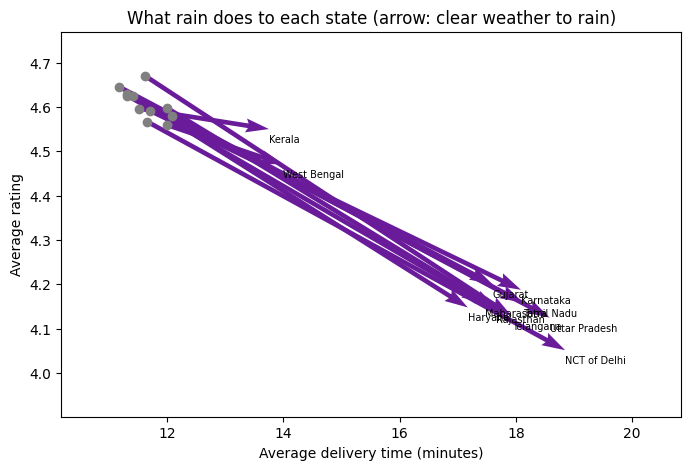

In [ ]:
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

developing matrics

In [ ]:
# A tiny example first
distance = np.array([1, 2, 3])
basket   = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


step 2
dividing matrics


In [ ]:
dist_values   = np.linspace(0.3, 4, 40)     # 40 distances, 0.3 to 4 km
basket_values = np.linspace(1, 12, 40)      # 40 basket sizes, 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Number of what-if cases: 1600


step 3 liner regreation - predition

In [ ]:
# A simple formula from our data: delivery time from distance and basket size

from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

Each extra km adds about 3.1 minutes
Each extra item adds about 0.31 minutes


what if case


In [ ]:
# Fill every what-if case with the expected delivery time
cases = pd.DataFrame({
    "Distance_KM": D.ravel(),
    "Basket_Size": B.ravel()
})

T = formula.predict(cases).reshape(D.shape)

how far can a store deliver for a given basket and still keep the 10 min promise


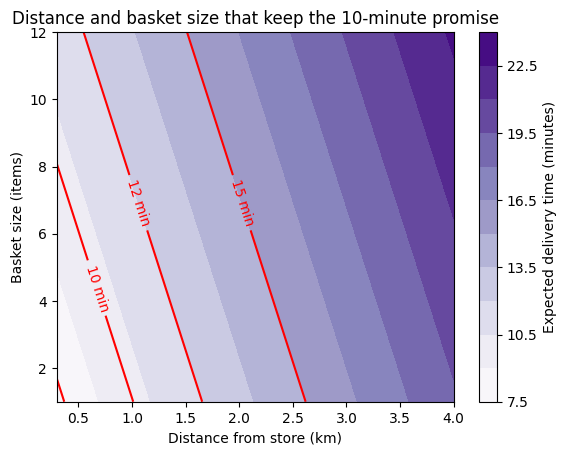

In [ ]:
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()

lecture 11


how did the sales build up week by week in each state

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Ensure the 'Week' column is present before pivoting
if "Week" not in df.columns:
    df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)

# Running total of sales, week by week, for each state
running = df.pivot_table(
    index='Week',
    columns='State',
    values='Order_Value',
    aggfunc='sum'
).fillna(0).cumsum()

running = running[running.iloc[-1].sort_values().index]  # smallest to largest

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

def draw(i):
    ax.clear()
    # Use the frame index 'i' to display cumulative sales up to that frame's week
    ax.barh(running.columns, running.iloc[i] / 1000, color="#6A189A")
    ax.set_xlim(0, running.values.max() / 1000 * 1.1)
    ax.set_title("Sales up to week " + str(running.index[i]))
    ax.set_xlabel("Sales (INR thousand)")

animation = FuncAnimation(fig, draw, frames=len(running), interval=700)

plt.close()
HTML(animation.to_jshtml())

count plot

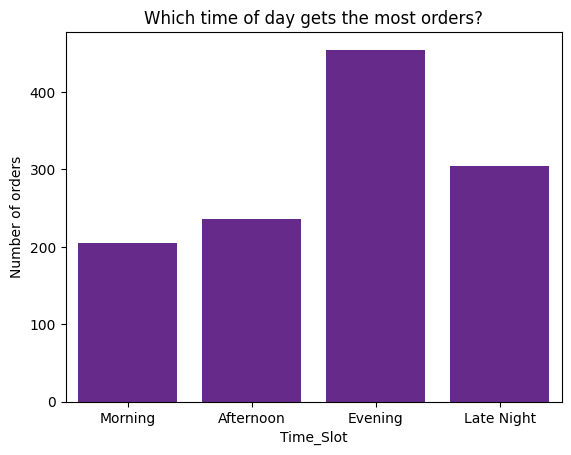

In [ ]:
import seaborn as sns

sns.countplot(
    data=df,
    x="Time_Slot",
    order=slot_order,
    color="#6A1B9A"
)

plt.title("Which time of day gets the most orders?")
plt.ylabel("Number of orders")
plt.show()

which slot is the busiest slot

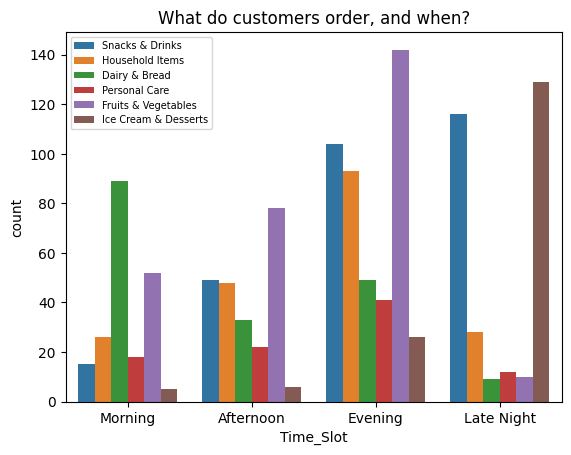

In [ ]:
sns.countplot(
    data=df,
    x="Time_Slot",
    order=slot_order,
    hue="Category"
)

plt.title("What do customers order, and when?")
plt.legend(fontsize=7)
plt.show()

which time slot has least preditable delivery

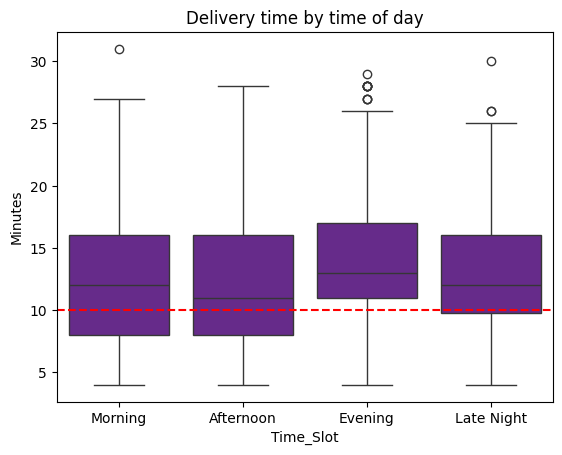

In [ ]:
sns.boxplot(
    data=df,
    x="Time_Slot",
    y="Delivery_Time_Min",
    order=slot_order,
    color="#6A1B9A"
)

plt.axhline(10, color="red", linestyle="--")

plt.title("Delivery time by time of day")
plt.ylabel("Minutes")
plt.show()

do pass members diffrentely from new usesrs?

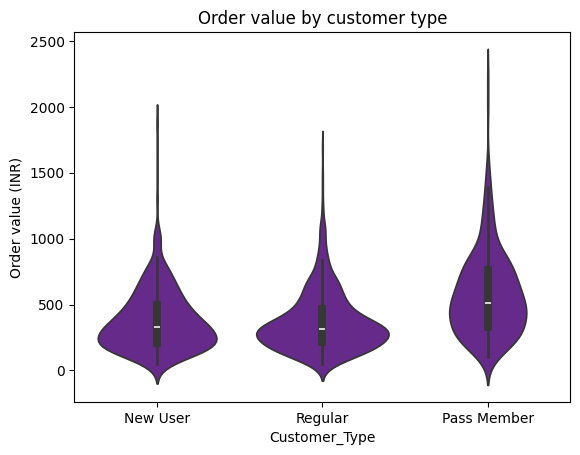

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the custom categorical order for customer types
type_order = ["New User", "Regular", "Pass Member"]

sns.violinplot(
    data=df,
    x="Customer_Type",
    y="Order_Value",
    order=type_order,
    color="#6A1B9A"
)

plt.title("Order value by customer type")
plt.ylabel("Order value (INR)")
plt.show()

are low rating caused by many orders or by few

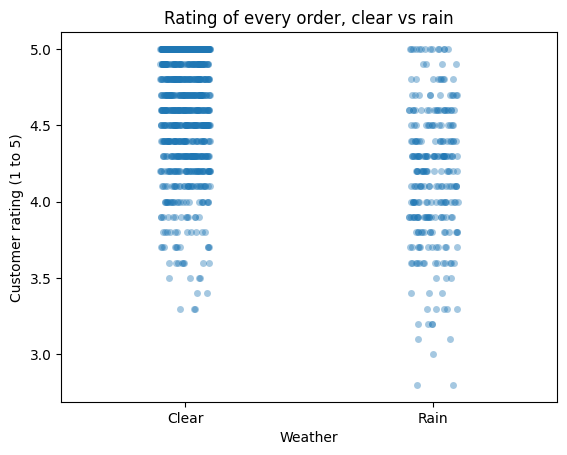

In [ ]:
sns.stripplot(
    data=df,
    x="Weather",
    y="Customer_Rating",
    jitter=True,
    alpha=0.4
)

plt.title("Rating of every order, clear vs rain")
plt.ylabel("Customer rating (1 to 5)")
plt.show()

do pass members really buy bigger basket - swarm plot

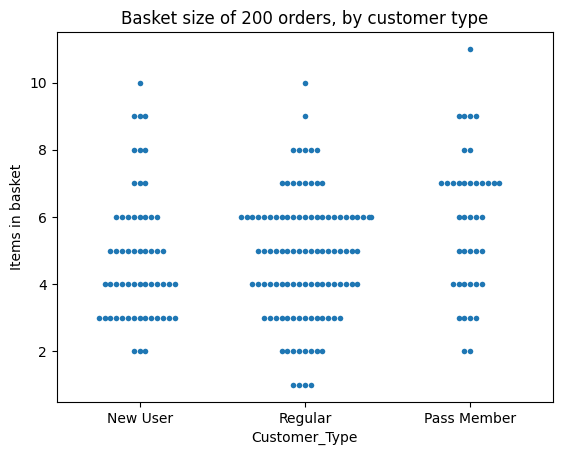

In [ ]:
sample = df.sample(200, random_state=1)

sns.swarmplot(
    data=sample,
    x="Customer_Type",
    y="Basket_Size",
    order=type_order,
    size=4
)

plt.title("Basket size of 200 orders, by customer type")
plt.ylabel("Items in basket")
plt.show()

lecture 13



liner regretaion and pca


In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Starbucks_Stores_Data.xlsx", sheet_name="Stores")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])

df.head()

Rows: 300 | Columns: 25


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,5.6,4.9,5.7,6.2,6.1,5.0,14.5,281,35.3,79.2
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,6.8,7.1,7.1,6.3,7.0,6.2,14.7,280,40.4,79.9
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,9.0,8.8,9.4,8.8,8.5,3.5,16.1,362,46.1,84.1
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,6.8,6.8,7.2,7.2,7.2,4.8,15.9,291,39.5,85.9
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,6.7,5.6,6.1,7.1,6.3,5.1,19.1,296,37.5,123.0


In [2]:
# Descriptive Statistics

# Display descriptive statistics for the dataset
print("DESCRIPTIVE STATISTICS")

display(df.describe().round(2))

# Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# Check missing values in each column
print("MISSING VALUES")
print(df.isnull().sum())

# Calculate mean, median, and mode
print("MEAN")
display(df.mean(numeric_only=True).round(2))

print("MEDIAN")
display(df.median(numeric_only=True).round(2))

print("MODE")
display(df.mode().head(1))

DESCRIPTIVE STATISTICS


,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,Promo_Offers_Count,App_Orders_Share_Pct,Loyalty_Members_K,App_Rating,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
count,300.0,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00,...,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,1192.8,45.27,11.67,128.36,86.18,54.04,6.22,25.04,21.62,4.23,...,7.30,6.97,7.47,7.26,7.38,6.13,15.88,310.51,39.38,88.77
std,343.4,13.54,3.10,46.20,33.80,22.44,2.37,7.18,7.36,0.27,...,0.80,1.01,0.79,0.76,0.89,1.51,4.18,25.22,6.79,20.30
min,500.0,14.00,5.00,30.00,15.00,8.00,1.00,6.00,4.00,3.40,...,4.90,4.20,5.70,5.00,4.30,2.50,5.00,235.00,15.00,45.50
25%,950.0,37.00,9.00,95.00,62.75,39.75,4.00,20.30,16.65,4.07,...,6.80,6.30,6.98,6.80,6.80,5.00,12.90,294.00,35.20,75.57
50%,1210.0,45.00,12.00,127.00,85.00,54.00,6.00,25.75,22.00,4.20,...,7.30,7.00,7.40,7.30,7.30,6.00,15.90,310.00,40.00,86.10
75%,1440.0,54.00,14.00,158.00,109.00,69.00,8.00,30.00,26.50,4.40,...,7.82,7.70,8.00,7.70,8.00,7.20,18.62,327.00,44.00,98.12
max,2000.0,80.00,19.00,260.00,179.00,120.00,13.00,48.00,40.10,4.90,...,9.70,10.00,9.70,9.20,9.70,11.10,26.60,382.00,58.10,170.80


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Store_ID                  300 non-null    object 
 1   City                      300 non-null    object 
 2   City_Tier                 300 non-null    object 
 3   Location_Type             300 non-null    object 
 4   Store_Area_SqFt           300 non-null    int64  
 5   Seats                     300 non-null    int64  
 6   Staff_Count               300 non-null    int64  
 7   Social_Media_Spend_K      300 non-null    int64  
 8   Outdoor_Ad_Spend_K        300 non-null    int64  
 9   Influencer_Spend_K        300 non-null    int64  
 10  Promo_Offers_Count        300 non-null    int64  
 11  App_Orders_Share_Pct      300 non-null    float64
 12  Loyalty_Members_K         300 non-null    float64
 13  App_Rating                300 non-null    flo

,0
Store_Area_SqFt,1192.80
Seats,45.27
Staff_Count,11.67
Social_Media_Spend_K,128.36
Outdoor_Ad_Spend_K,86.18
Influencer_Spend_K,54.04
Promo_Offers_Count,6.22
App_Orders_Share_Pct,25.04
Loyalty_Members_K,21.62
App_Rating,4.23


MEDIAN


,0
Store_Area_SqFt,1210.00
Seats,45.00
Staff_Count,12.00
Social_Media_Spend_K,127.00
Outdoor_Ad_Spend_K,85.00
Influencer_Spend_K,54.00
Promo_Offers_Count,6.00
App_Orders_Share_Pct,25.75
Loyalty_Members_K,22.00
App_Rating,4.20


MODE


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
0,ST-001,Chandigarh,Metro,Mall,1260.0,39.0,9.0,106.0,15.0,61.0,...,7.2,7.2,7.2,7.1,7.8,6.0,14.5,320.0,38.0,68.7


which busniess variable to be want to relate and what is their type



In [3]:
numbers = df.select_dtypes(include="number").columns.tolist()

categories = df.select_dtypes(exclude="number").columns.tolist()

print("Number variables:", len(numbers))

print("Category variables:", categories)

Number variables: 21
Category variables: ['Store_ID', 'City', 'City_Tier', 'Location_Type']


In [4]:
# The nine key variables we will use in Part C

key_cols = [
    "Social_Media_Spend_K",
    "App_Orders_Share_Pct",
    "Seats",
    "Staff_Count",
    "Avg_Wait_Time_Min",
    "Service_Score",
    "Repeat_Customer_Pct",
    "Monthly_Footfall_K",
    "Monthly_Sales_INR_Lakh"
]

print("Nine Key Variables:")
print(key_cols)

Nine Key Variables:
['Social_Media_Spend_K', 'App_Orders_Share_Pct', 'Seats', 'Staff_Count', 'Avg_Wait_Time_Min', 'Service_Score', 'Repeat_Customer_Pct', 'Monthly_Footfall_K', 'Monthly_Sales_INR_Lakh']


do stors with a high share of app orders sell more?

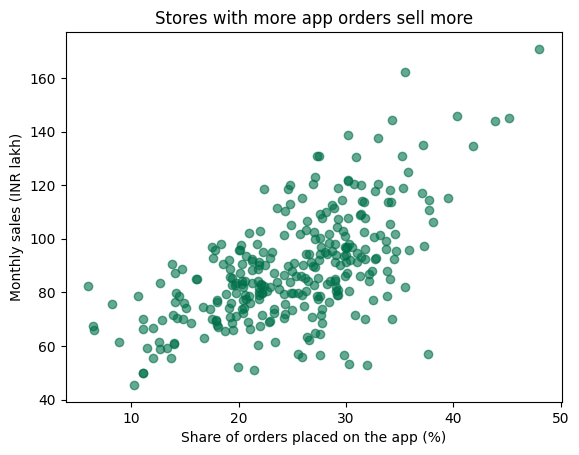

In [5]:
import matplotlib.pyplot as plt

plt.scatter(df["App_Orders_Share_Pct"], df["Monthly_Sales_INR_Lakh"], alpha=0.6, color="#00704A")
plt.title("Stores with more app orders sell more")
plt.xlabel("Share of orders placed on the app (%)")
plt.ylabel("Monthly sales (INR lakh)")
plt.show()

do longer weights means fewer repert customers now prepare graph between avg wait time and reperted customer


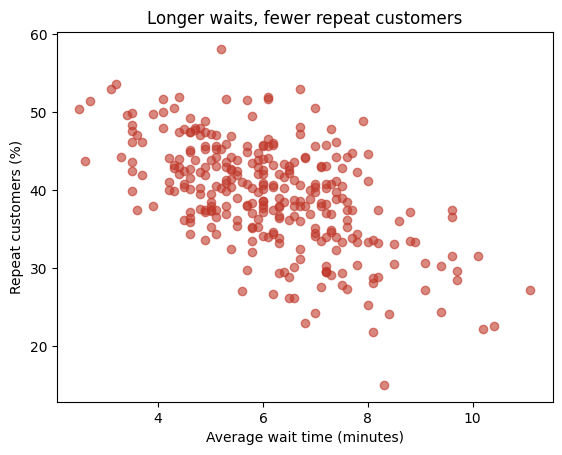

In [6]:
plt.scatter(df["Avg_Wait_Time_Min"], df["Repeat_Customer_Pct"], alpha=0.6, color="#C0392B")
plt.title("Longer waits, fewer repeat customers")
plt.xlabel("Average wait time (minutes)")
plt.ylabel("Repeat customers (%)")
plt.show()

no relationship - does a  bigger store have better coffee ?

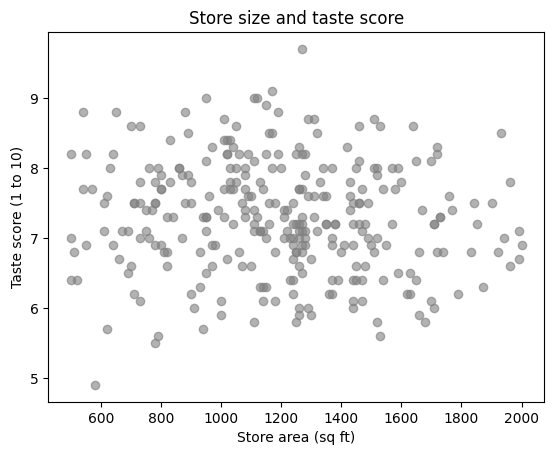

In [7]:
plt.scatter(df["Store_Area_SqFt"], df["Taste_Score"], alpha=0.6, color="grey")
plt.title("Store size and taste score")
plt.xlabel("Store area (sq ft)")
plt.ylabel("Taste score (1 to 10)")
plt.show()

co relation cofficient how strong is a relationship and in which direction


In [8]:
r1 = df["App_Orders_Share_Pct"].corr(df["Monthly_Sales_INR_Lakh"])
r2 = df["Avg_Wait_Time_Min"].corr(df["Repeat_Customer_Pct"])
r3 = df["Store_Area_SqFt"].corr(df["Taste_Score"])

print("App share and sales       :", round(r1, 2))
print("Wait time and repeat      :", round(r2, 2))
print("Store area and taste      :", round(r3, 2))

App share and sales       : 0.61
Wait time and repeat      : -0.58
Store area and taste      : -0.09


co relation matrix


how are all the key variables relate to each other



In [9]:
corr = df[key_cols].corr().round(2)
corr

,Social_Media_Spend_K,App_Orders_Share_Pct,Seats,Staff_Count,Avg_Wait_Time_Min,Service_Score,Repeat_Customer_Pct,Monthly_Footfall_K,Monthly_Sales_INR_Lakh
Social_Media_Spend_K,1.00,0.40,-0.00,0.03,-0.01,-0.06,-0.02,0.32,0.67
App_Orders_Share_Pct,0.40,1.00,-0.03,-0.02,0.03,-0.03,-0.03,0.44,0.61
Seats,-0.00,-0.03,1.00,0.75,0.13,-0.09,-0.07,0.53,0.37
Staff_Count,0.03,-0.02,0.75,1.00,0.07,-0.01,-0.04,0.54,0.30
Avg_Wait_Time_Min,-0.01,0.03,0.13,0.07,1.00,-0.26,-0.58,-0.05,0.04
Service_Score,-0.06,-0.03,-0.09,-0.01,-0.26,1.00,0.75,0.25,-0.01
Repeat_Customer_Pct,-0.02,-0.03,-0.07,-0.04,-0.58,0.75,1.00,0.17,-0.01
Monthly_Footfall_K,0.32,0.44,0.53,0.54,-0.05,0.25,0.17,1.00,0.59
Monthly_Sales_INR_Lakh,0.67,0.61,0.37,0.30,0.04,-0.01,-0.01,0.59,1.00


heat map


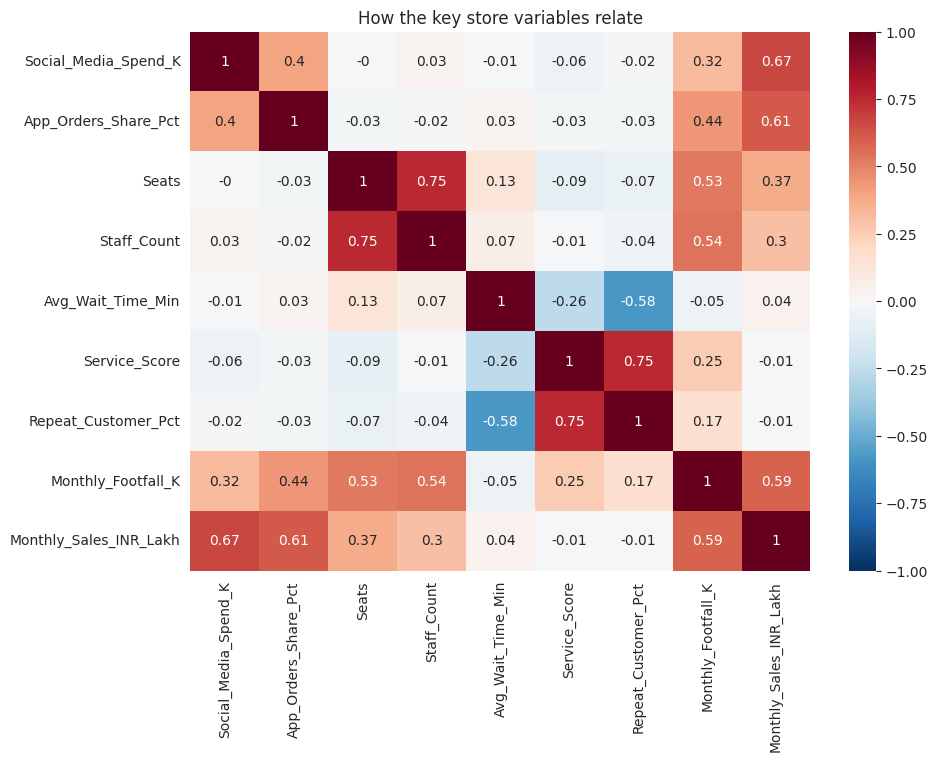

In [11]:
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the key store variables relate")
plt.show()

liner regression

statical modeling

In [12]:
import statsmodels.formula.api as smf

m_social = smf.ols("Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K", data=df).fit()

print(m_social.summary().tables[1])
print("R-squared:", round(m_social.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               50.9018      2.574     19.775      0.000      45.836      55.967
Social_Media_Spend_K     0.2950      0.019     15.631      0.000       0.258       0.332
R-squared: 0.45


interpretatioon a unit increse social media spending is associated with a rs 0.295L increse in montly sales

socail meadia expending 45% of veriation in montly sales

p value socail meadia spending as a statical singificate postive with montly sales

multiple liner regretion what are the affect of some variables on montly sales

In [13]:
m_multi = smf.ols("Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K + App_Orders_Share_Pct + Seats", data=df).fit()

print(m_multi.summary().tables[1])
print("R-squared:", round(m_multi.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                4.8896      3.176      1.539      0.125      -1.361      11.140
Social_Media_Spend_K     0.2226      0.014     15.497      0.000       0.194       0.251
App_Orders_Share_Pct     1.1821      0.093     12.779      0.000       1.000       1.364
Seats                    0.5677      0.045     12.614      0.000       0.479       0.656
R-squared: 0.73


lecture 14 multiple lenier rgression and principal effect


does staff count realy matters once store size is held fixed

In [14]:
m_staff_alone = smf.ols("Monthly_Sales_INR_Lakh ~ Staff_Count", data=df).fit()
m_staff_ctrl = smf.ols("Monthly_Sales_INR_Lakh ~ Staff_Count + Seats", data=df).fit()

print(m_staff_alone.summary().tables[1])
print("R-squared:", round(m_staff_alone.rsquared, 2))

print(m_staff_ctrl.summary().tables[1])
print("R-squared:", round(m_staff_ctrl.rsquared, 2))

print("Staff effect alone:", round(m_staff_alone.params["Staff_Count"], 2),
      "| p-value:", round(m_staff_alone.pvalues["Staff_Count"], 3))

print("Staff effect with Seats:", round(m_staff_ctrl.params["Staff_Count"], 2),
      "| p-value:", round(m_staff_ctrl.pvalues["Staff_Count"], 3))

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      66.0724      4.371     15.115      0.000      57.470      74.675
Staff_Count     1.9441      0.362      5.371      0.000       1.232       2.656
R-squared: 0.09
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      62.4999      4.354     14.356      0.000      53.932      71.068
Staff_Count     0.3474      0.530      0.656      0.512      -0.695       1.390
Seats           0.4907      0.121      4.043      0.000       0.252       0.730
R-squared: 0.14
Staff effect alone: 1.94 | p-value: 0.0
Staff effect with Seats: 0.35 | p-value: 0.512


interpretation

In [17]:
m_multi = smf.ols("Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K + App_Orders_Share_Pct + Seats", data=df).fit()

print(m_multi.summary().tables[1])
print("R-squared:", round(m_multi.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                4.8896      3.176      1.539      0.125      -1.361      11.140
Social_Media_Spend_K     0.2226      0.014     15.497      0.000       0.194       0.251
App_Orders_Share_Pct     1.1821      0.093     12.779      0.000       1.000       1.364
Seats                    0.5677      0.045     12.614      0.000       0.479       0.656
R-squared: 0.73


In [18]:
print("\nINTERPRETATION:")

print("1. Staff Count alone has a positive and significant effect on sales "
      "(Coefficient = 1.9441, p < 0.001). It explains 9% of sales variation.")

print("2. After controlling for Seats, Staff Count becomes insignificant "
      "(Coefficient = 0.3474, p = 0.512).")

print("3. Seats has a positive and significant effect on sales "
      "(Coefficient = 0.4907, p < 0.001).")

print("4. R-squared increases from 0.09 to 0.14.")

print("\nConclusion: Seats is a significant predictor of monthly sales, "
      "while Staff Count is not significant after controlling for Seats.")


INTERPRETATION:
1. Staff Count alone has a positive and significant effect on sales (Coefficient = 1.9441, p < 0.001). It explains 9% of sales variation.
2. After controlling for Seats, Staff Count becomes insignificant (Coefficient = 0.3474, p = 0.512).
3. Seats has a positive and significant effect on sales (Coefficient = 0.4907, p < 0.001).
4. R-squared increases from 0.09 to 0.14.

Conclusion: Seats is a significant predictor of monthly sales, while Staff Count is not significant after controlling for Seats.


moderaton effect / intraction effect

does social spending effect depends upon how digital the store is?

In [20]:
#info
#centrilziation of variable

In [21]:
# Centre the numbers: subtract the average

df['Social_c'] = df['Social_Media_Spend_K'] - df['Social_Media_Spend_K'].mean()

df['App_c'] = df['App_Orders_Share_Pct'] - df['App_Orders_Share_Pct'].mean()

df['Wait_c'] = df['Avg_Wait_Time_Min'] - df['Avg_Wait_Time_Min'].mean()

df['Service_c'] = df['Service_Score'] - df['Service_Score'].mean()


# A yes or no flag: 1 = Metro store, 0 = other

df['Is_Metro'] = (df['City_Tier'] == 'Metro').astype(int)

moderation  effect of application

In [22]:
m_digital = smf.ols("Monthly_Sales_INR_Lakh ~ Social_c * App_c", data=df).fit()

print(m_digital.summary().tables[1])
print("R-squared:", round(m_digital.rsquared, 2))

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         86.0459      0.685    125.677      0.000      84.698      87.393
Social_c           0.2270      0.015     15.076      0.000       0.197       0.257
App_c              1.1605      0.097     11.975      0.000       0.970       1.351
Social_c:App_c     0.0208      0.002     10.881      0.000       0.017       0.025
R-squared: 0.71


step 3 checking the moradion effect thorugh visulization / liner model effect

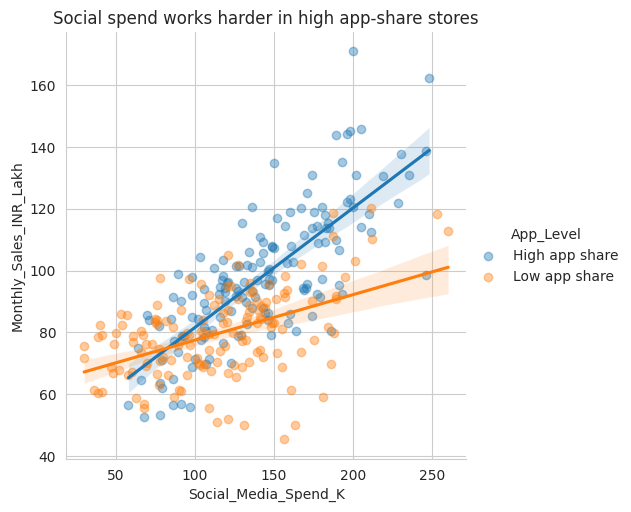

In [23]:
df["App_Level"] = np.where(df["App_Orders_Share_Pct"] > df["App_Orders_Share_Pct"].median(), "High app share", "Low app share")

g = sns.lmplot(data=df, x="Social_Media_Spend_K", y="Monthly_Sales_INR_Lakh", hue="App_Level", height=5, scatter_kws={"alpha": 0.4})

g.set(title="Social spend works harder in high app-share stores")

plt.show()

pricipal component analysis

In [24]:
groups = {
    "Customer Experience": ["Taste_Score", "Service_Score", "Cleanliness_Score", "Ambience_Score", "Staff_Friendliness_Score"],
    "Digital Engagement": ["App_Orders_Share_Pct", "Loyalty_Members_K", "App_Rating", "Social_Followers_K"],
    "Marketing Intensity": ["Social_Media_Spend_K", "Outdoor_Ad_Spend_K", "Influencer_Spend_K", "Promo_Offers_Count"],
    "Store Capacity": ["Store_Area_SqFt", "Seats", "Staff_Count"],
}

for name, cols in groups.items():
    c = df[cols].corr().values
    average = (c.sum() - len(cols)) / (len(cols) * (len(cols) - 1))  # average correlation inside the group
    print(f"{name}: {len(cols)} variables, average correlation {average:.2f}")

Customer Experience: 5 variables, average correlation 0.79
Digital Engagement: 4 variables, average correlation 0.77
Marketing Intensity: 4 variables, average correlation 0.74
Store Capacity: 3 variables, average correlation 0.77


In [26]:
cols = ['Taste_Score', 'Service_Score', 'Cleanliness_Score', 'Ambience_Score', 'Staff_Friendliness_Score']
cust_exp_corr = df[cols].corr().round(2)
display(cust_exp_corr)

,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score
Taste_Score,1.00,0.83,0.81,0.72,0.84
Service_Score,0.83,1.00,0.83,0.76,0.82
Cleanliness_Score,0.81,0.83,1.00,0.73,0.80
Ambience_Score,0.72,0.76,0.73,1.00,0.73
Staff_Friendliness_Score,0.84,0.82,0.80,0.73,1.00


pca 1 customer experience index

In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cols = groups["Customer Experience"]

# Step A: put every variable on the same scale
scaled = StandardScaler().fit_transform(df[cols])

# Step B: run PCA
pca = PCA()
scores = pca.fit_transform(scaled)

# Step C: how much does each component explain?
names = [f"PC{i+1}" for i in range(len(cols))]
print(pd.Series(pca.explained_variance_ratio_, index=names).round(2))

PC1    0.83
PC2    0.06
PC3    0.04
PC4    0.03
PC5    0.03
dtype: float64


In [28]:
# Step D: the loadings show how much each variable counts in PC1

sign = 1 if pca.components_[0].sum() > 0 else -1  # make sure a higher score means better

print(pd.Series(pca.components_[0] * sign, index=cols).round(2))

Taste_Score                 0.45
Service_Score               0.46
Cleanliness_Score           0.45
Ambience_Score              0.42
Staff_Friendliness_Score    0.45
dtype: float64


In [29]:
# Step E: turn PC1 into an index from 0 to 100

raw_index = scores[:, 0] * sign

df["Experience_Index"] = (raw_index - raw_index.min()) / (raw_index.max() - raw_index.min()) * 100

variance_explained = {"Experience_Index": round(pca.explained_variance_ratio_[0] * 100)}

print(df[["Store_ID", "Experience_Index"]].sort_values("Experience_Index").head(5).round(1))
df.head()

    Store_ID  Experience_Index
90    ST-091               0.0
56    ST-057              12.4
229   ST-230              13.4
114   ST-115              14.9
0     ST-001              15.1


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh,Social_c,App_c,Wait_c,Service_c,Is_Metro,App_Level,Experience_Index
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,281,35.3,79.2,0.636667,0.860667,-1.125333,-2.065667,1,High app share,15.053441
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,280,40.4,79.9,-33.363333,0.460667,0.074667,0.134333,0,Low app share,43.282122
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,362,46.1,84.1,-52.363333,-4.439333,-2.625333,1.834333,1,Low app share,95.125035
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,291,39.5,85.9,-75.363333,-5.839333,-1.325333,-0.165667,1,Low app share,48.250579
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,296,37.5,123.0,69.636667,2.060667,-1.025333,-1.365667,1,High app share,31.811512


pca 2 digital engagement index

In [30]:
def make_index(columns, index_name):
    scaled = StandardScaler().fit_transform(df[columns])
    pca = PCA().fit(scaled)
    scores = pca.transform(scaled)[:, 0]

    sign = 1 if pca.components_[0].sum() > 0 else -1
    scores = scores * sign

    df[index_name] = (scores - scores.min()) / (scores.max() - scores.min()) * 100
    variance_explained[index_name] = round(pca.explained_variance_ratio_[0] * 100)

    print("Variance explained by PC1:", variance_explained[index_name], "%")
    print(pd.Series(pca.components_[0] * sign, index=columns).round(2))


make_index(groups["Digital Engagement"], "Digital_Index")

Variance explained by PC1: 83 %
App_Orders_Share_Pct    0.51
Loyalty_Members_K       0.50
App_Rating              0.49
Social_Followers_K      0.51
dtype: float64


In [31]:
df.head()

,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh,Social_c,App_c,Wait_c,Service_c,Is_Metro,App_Level,Experience_Index,Digital_Index
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,35.3,79.2,0.636667,0.860667,-1.125333,-2.065667,1,High app share,15.053441,63.903468
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,40.4,79.9,-33.363333,0.460667,0.074667,0.134333,0,Low app share,43.282122,46.882338
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,46.1,84.1,-52.363333,-4.439333,-2.625333,1.834333,1,Low app share,95.125035,42.105136
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,39.5,85.9,-75.363333,-5.839333,-1.325333,-0.165667,1,Low app share,48.250579,37.583650
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,37.5,123.0,69.636667,2.060667,-1.025333,-1.365667,1,High app share,31.811512,59.778442


marketing intencity index

In [32]:
make_index(groups["Marketing Intensity"], "Marketing_Index")

Variance explained by PC1: 80 %
Social_Media_Spend_K    0.52
Outdoor_Ad_Spend_K      0.51
Influencer_Spend_K      0.49
Promo_Offers_Count      0.49
dtype: float64


pca 4 store capicity index

In [33]:
make_index(groups["Store Capacity"], "Capacity_Index")

Variance explained by PC1: 85 %
Store_Area_SqFt    0.58
Seats              0.58
Staff_Count        0.57
dtype: float64


In [34]:
df.head()

,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Social_c,App_c,Wait_c,Service_c,Is_Metro,App_Level,Experience_Index,Digital_Index,Marketing_Index,Capacity_Index
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,0.636667,0.860667,-1.125333,-2.065667,1,High app share,15.053441,63.903468,49.757078,26.165014
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,-33.363333,0.460667,0.074667,0.134333,0,Low app share,43.282122,46.882338,25.812761,60.440122
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,-52.363333,-4.439333,-2.625333,1.834333,1,Low app share,95.125035,42.105136,31.846963,40.440952
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,-75.363333,-5.839333,-1.325333,-0.165667,1,Low app share,48.250579,37.583650,23.357711,92.888862
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,69.636667,2.060667,-1.025333,-1.365667,1,High app share,31.811512,59.778442,72.164804,57.980817


checking co relation for all the index

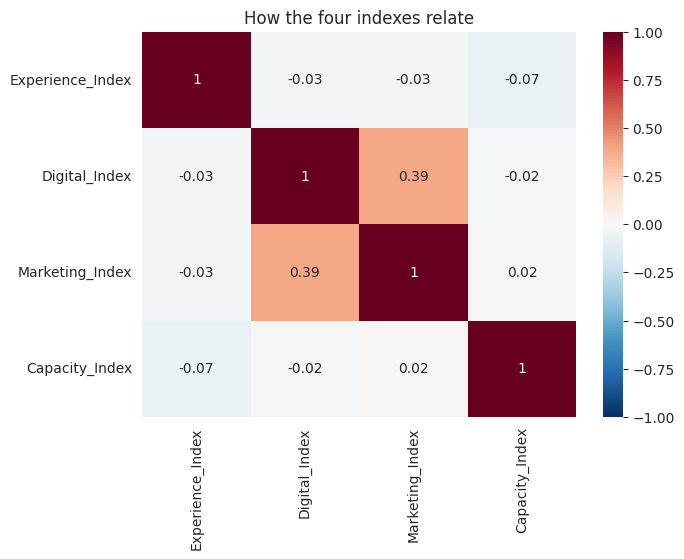

In [36]:
index_cols = ["Experience_Index", "Digital_Index", "Marketing_Index", "Capacity_Index"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[index_cols].corr().round(2), annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the four indexes relate")
plt.show()